In [1]:
from pipeline import PipelineEDA

## 1. Cargar

In [2]:
pipeline = PipelineEDA("data/online_retail.csv")
pipeline.df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Análisis inicial

In [3]:
pipeline.analizar()

ARCHIVO: online_retail.csv

INFORMACION GENERAL DEL DATASET:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


            Quantity      UnitPrice     CustomerID
count  541909.000000  541909.000000  406829.000000
mean        9.552250       4.611114   15287.690570
std       218.081158      96.759853    1713.600303
min    -80995.000000  -11062.060000   12346.000000
25%         1.000000       1.250000   13953.000000
50%         3.000000       2

## 3. Nulos

In [4]:
pipeline.tratar_nulos(["CustomerID"])

Se eliminaron los nulos de: CustomerID


In [5]:
pipeline.ver_nulos()


ANALISIS DE VALORES NULOS

TABLA DE VALORES NULOS:
             Cantidad de nulos  Porcentaje de nulos
InvoiceNo                    0                  0.0
StockCode                    0                  0.0
Description                  0                  0.0
Quantity                     0                  0.0
InvoiceDate                  0                  0.0
UnitPrice                    0                  0.0
CustomerID                   0                  0.0
Country                      0                  0.0

TOTAL DE VALORES NULOS:
0


## 4. Duplicados

In [6]:
pipeline.ver_duplicados()

Filas duplicadas: 5,225


In [7]:
pipeline.eliminar_duplicados()

Filas eliminadas: 5,225
Filas restantes: 401,604


## 5. Facturas canceladas

In [8]:
pipeline.filtrar_facturas_canceladas(obtener=True).head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [9]:
pipeline.filtrar_facturas_canceladas()


Se eliminaron las facturas canceladas.


## 6. Cantidades y precios inválidos

In [10]:
pipeline.filtrar_ventas_positivas()

Filas eliminadas: 40
Filas restantes: 392,692


## 7. Códigos que no son productos

In [11]:
no_productos = ["POST", "DOT", "M", "D", "C2", "S", "BANK CHARGES", "AMAZONFEE", "CRUK", "PADS"]

In [12]:
pipeline.filtrar_codigos_no_producto(no_productos, obtener=True)['Description'].value_counts()

Description
POSTAGE                       1099
Manual                         279
CARRIAGE                       133
DOTCOM POSTAGE                  16
Bank Charges                    12
PADS TO MATCH ALL CUSHIONS       3
Name: count, dtype: int64

In [13]:
pipeline.filtrar_codigos_no_producto(no_productos)

Filas eliminadas: 1,542
Filas restantes: 391,150


## 8. Descripciones

In [14]:
pipeline.limpiar_descripciones()

Filas corregidas: 94,033


## 9. Tipos de datos

In [15]:
pipeline.convertir_tipos(columnas_int=["CustomerID"], columnas_fecha=["InvoiceDate"])

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              Int64
Country                object
dtype: object


## 10. Outliers

In [16]:
pipeline.df[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,391150.000000,391150.000000
mean,13.145300,2.874372
std,180.807831,4.284738
min,1.000000,0.040000
25%,2.000000,1.250000
50%,6.000000,1.950000
75%,12.000000,3.750000
max,80995.000000,649.500000


In [17]:
pipeline.eliminar_outliers(["Quantity", "UnitPrice"])

Quantity: limite = 120.00
UnitPrice: limite = 12.75
Filas eliminadas: 7,384
Filas restantes: 383,766


In [18]:
pipeline.df[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,383766.000000,383766.000000
mean,10.030761,2.696806
std,14.657576,2.464347
min,1.000000,0.040000
25%,2.000000,1.250000
50%,6.000000,1.850000
75%,12.000000,3.750000
max,120.000000,12.750000


## 11. Columnas nuevas

In [19]:
pipeline.crear_columnas()

Columnas nuevas: Total, Mes, Dia, Hora


In [20]:
pipeline.df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Total,Mes,Dia,Hora
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8


## 12. Resultado

In [21]:
pipeline.resumen_limpieza()

RESUMEN DE LIMPIEZA
Filas iniciales: 541,909
Filas finales: 383,766
Eliminadas: 158,143 (29.2%)
Nulos restantes: 0
Duplicados restantes: 0


In [22]:
pipeline.guardar("online_retail_limpio.csv")

Guardado en: online_retail_limpio.csv


### EDA

RESUMEN GENERAL
Facturas : 17,951
Clientes : 4,289
Productos: 3,610
Países   : 37
Ventas   : 6,846,370.96


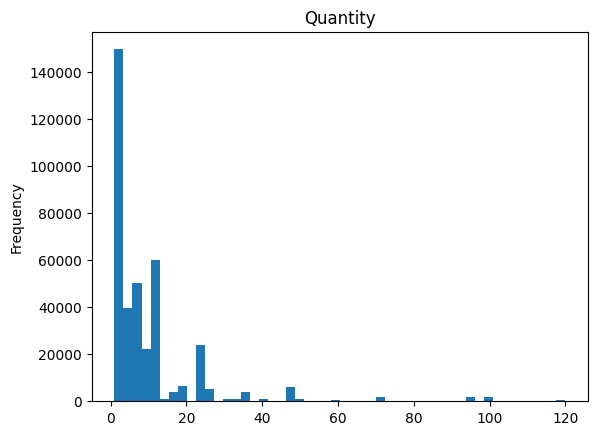

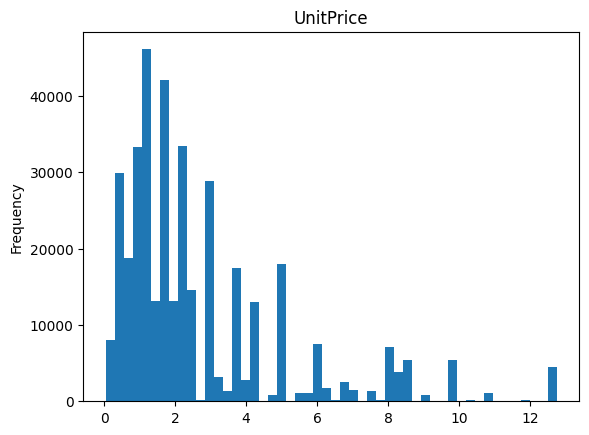

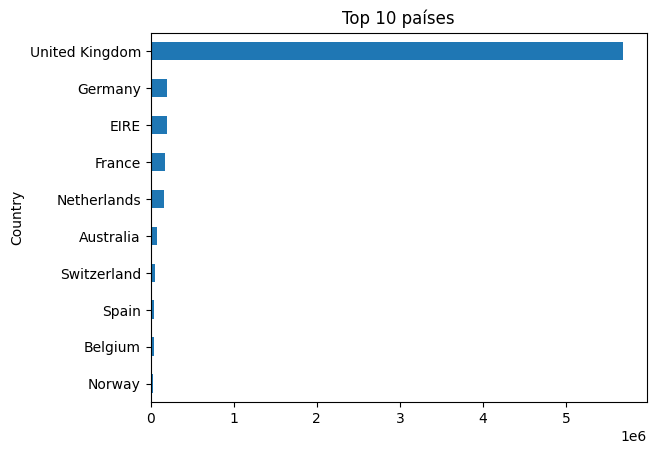

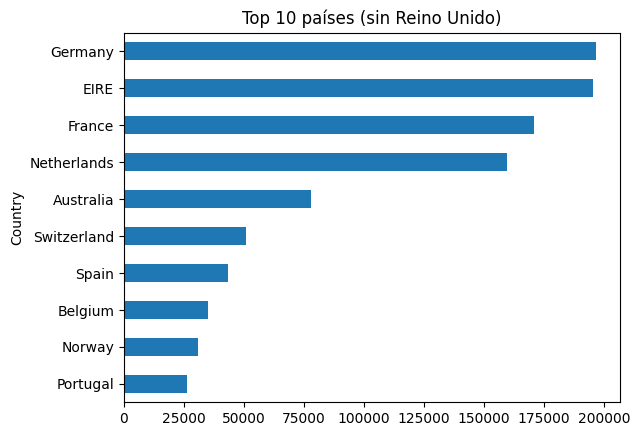

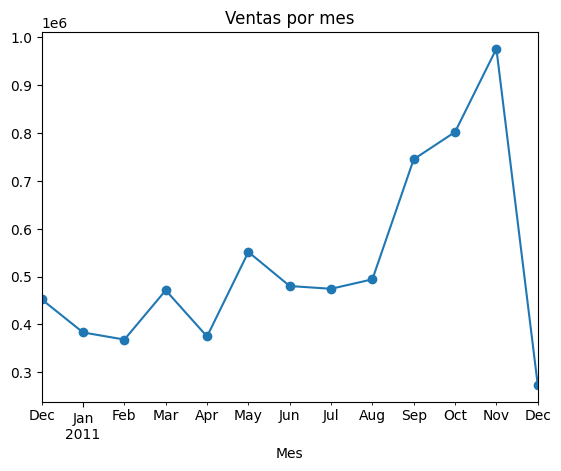

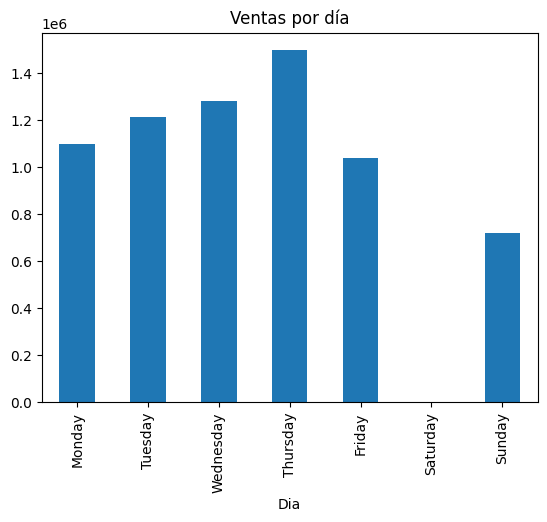

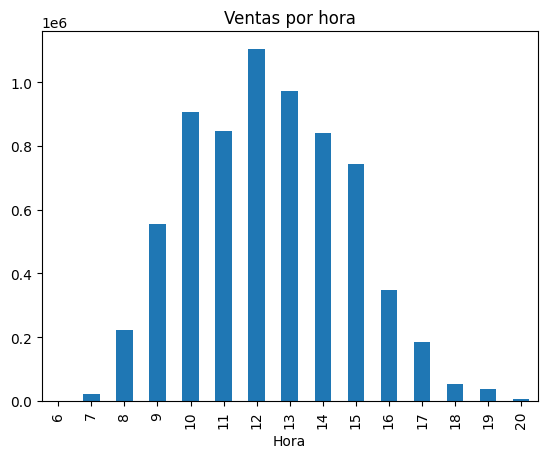

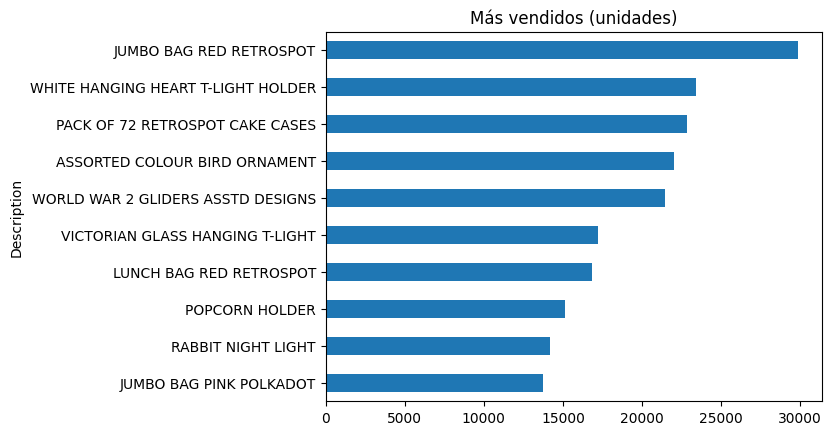

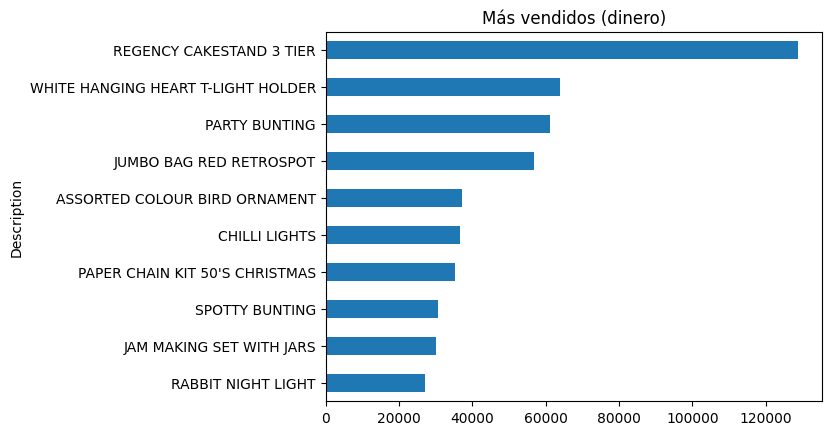


TOP 10 CLIENTES POR VENTAS
CustomerID
14646    154991.10
14911    124091.32
17511     73056.39
14156     67860.24
18102     66370.00
12415     65628.97
15311     56440.96
13089     54827.66
14088     48311.16
14096     47448.70
Name: Total, dtype: float64


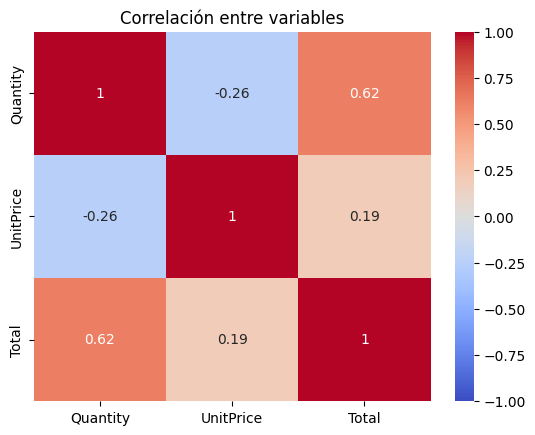

In [23]:
pipeline.eda()

## Reglas de asociación

In [24]:
reglas = PipelineEDA("online_retail_limpio.csv")

### 13. Transacciones (factura = canasta, producto = ítem)

In [25]:
reglas.preparar_transacciones()

TRANSACCIONES PARA REGLAS DE ASOCIACION
Transacciones (facturas): 17,951
Productos distintos     : 3,795
Items por factura       : promedio 21.1 | maximo 521


### 14. Apriori

In [26]:
reglas.apriori(min_soporte=0.01, max_len=4).head(10)

[apriori] itemsets frecuentes: 1,021 | tiempo: 2.24 s


,itemsets,conteo,soporte,longitud
0,(WHITE HANGING HEART T-LIGHT HOLDER),1934,0.107738,1
1,(REGENCY CAKESTAND 3 TIER),1686,0.093922,1
2,(JUMBO BAG RED RETROSPOT),1542,0.085901,1
3,(PARTY BUNTING),1367,0.076152,1
4,(ASSORTED COLOUR BIRD ORNAMENT),1322,0.073645,1
5,(LUNCH BAG RED RETROSPOT),1284,0.071528,1
6,(SET OF 3 CAKE TINS PANTRY DESIGN),1141,0.063562,1
7,(LUNCH BAG BLACK SKULL.),1051,0.058548,1
8,(LUNCH BAG SUKI DESIGN),1040,0.057935,1
9,(PACK OF 72 RETROSPOT CAKE CASES),1008,0.056153,1


### 15. FP-Growth

In [27]:
reglas.fp_growth(min_soporte=0.01, max_len=4).head(10)

[fp_growth] itemsets frecuentes: 1,021 | tiempo: 1.54 s


,itemsets,conteo,soporte,longitud
0,(WHITE HANGING HEART T-LIGHT HOLDER),1934,0.107738,1
1,(REGENCY CAKESTAND 3 TIER),1686,0.093922,1
2,(JUMBO BAG RED RETROSPOT),1542,0.085901,1
3,(PARTY BUNTING),1367,0.076152,1
4,(ASSORTED COLOUR BIRD ORNAMENT),1322,0.073645,1
5,(LUNCH BAG RED RETROSPOT),1284,0.071528,1
6,(SET OF 3 CAKE TINS PANTRY DESIGN),1141,0.063562,1
7,(LUNCH BAG BLACK SKULL.),1051,0.058548,1
8,(LUNCH BAG SUKI DESIGN),1040,0.057935,1
9,(PACK OF 72 RETROSPOT CAKE CASES),1008,0.056153,1


### 16. Eclat

In [28]:
reglas.eclat(min_soporte=0.01, max_len=4).head(10)

[eclat] itemsets frecuentes: 1,021 | tiempo: 0.30 s


,itemsets,conteo,soporte,longitud
0,(WHITE HANGING HEART T-LIGHT HOLDER),1934,0.107738,1
1,(REGENCY CAKESTAND 3 TIER),1686,0.093922,1
2,(JUMBO BAG RED RETROSPOT),1542,0.085901,1
3,(PARTY BUNTING),1367,0.076152,1
4,(ASSORTED COLOUR BIRD ORNAMENT),1322,0.073645,1
5,(LUNCH BAG RED RETROSPOT),1284,0.071528,1
6,(SET OF 3 CAKE TINS PANTRY DESIGN),1141,0.063562,1
7,(LUNCH BAG BLACK SKULL.),1051,0.058548,1
8,(LUNCH BAG SUKI DESIGN),1040,0.057935,1
9,(PACK OF 72 RETROSPOT CAKE CASES),1008,0.056153,1


### 17. Comparación de los tres algoritmos

In [29]:
reglas.comparar_algoritmos(min_soporte=0.01, max_len=4)

COMPARACION DE ALGORITMOS (min_soporte=0.01, max_len=4)
[apriori] itemsets frecuentes: 1,021 | tiempo: 1.88 s
[fp_growth] itemsets frecuentes: 1,021 | tiempo: 1.28 s
[eclat] itemsets frecuentes: 1,021 | tiempo: 0.28 s

Los tres encuentran los mismos itemsets con los mismos conteos: True


,algoritmo,itemsets,tiempo_s
0,apriori,1021,1.877
1,fp_growth,1021,1.276
2,eclat,1021,0.280


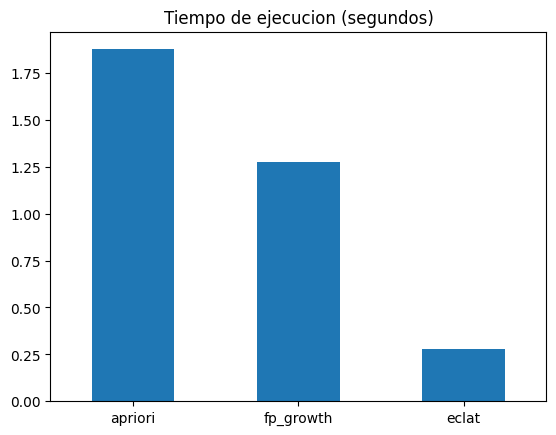

In [30]:
reglas.graficar_tiempos()

### 18. Itemsets frecuentes

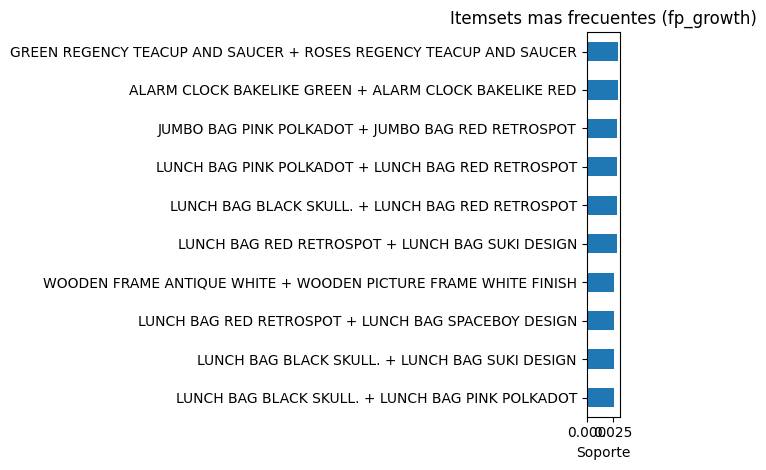

In [31]:
reglas.graficar_itemsets("fp_growth", n=10, longitud_minima=2)

### 19. Reglas de asociación

In [32]:
reglas.generar_reglas("fp_growth", min_confianza=0.5, min_lift=1.2).head()

[fp_growth] reglas generadas: 328 (confianza >= 0.5, lift >= 1.2)


,antecedentes,consecuentes,soporte_antecedente,soporte_consecuente,soporte,confianza,lift,leverage,conviccion
0,(REGENCY TEA PLATE PINK),"(REGENCY TEA PLATE GREEN, REGENCY TEA PLATE RO...",0.012423,0.012590,0.010250,0.825112,65.537998,0.010094,5.645961
1,"(REGENCY TEA PLATE GREEN, REGENCY TEA PLATE RO...",(REGENCY TEA PLATE PINK),0.012590,0.012423,0.010250,0.814159,65.537998,0.010094,5.314106
2,"(REGENCY TEA PLATE PINK, REGENCY TEA PLATE ROSES)",(REGENCY TEA PLATE GREEN),0.010919,0.014874,0.010250,0.938776,63.115952,0.010088,16.090394
3,(REGENCY TEA PLATE GREEN),"(REGENCY TEA PLATE PINK, REGENCY TEA PLATE ROSES)",0.014874,0.010919,0.010250,0.689139,63.115952,0.010088,3.181744
4,(REGENCY TEA PLATE PINK),(REGENCY TEA PLATE GREEN),0.012423,0.014874,0.011197,0.901345,60.599436,0.011012,9.985597


In [33]:
reglas.top_reglas("fp_growth", n=10, ordenar_por="lift")

,antecedentes,consecuentes,soporte,confianza,lift
0,REGENCY TEA PLATE GREEN + REGENCY TEA PLATE ROSES,REGENCY TEA PLATE PINK,0.010,0.814,65.538
1,REGENCY TEA PLATE PINK,REGENCY TEA PLATE GREEN + REGENCY TEA PLATE ROSES,0.010,0.825,65.538
2,REGENCY TEA PLATE PINK + REGENCY TEA PLATE ROSES,REGENCY TEA PLATE GREEN,0.010,0.939,63.116
3,REGENCY TEA PLATE GREEN,REGENCY TEA PLATE PINK + REGENCY TEA PLATE ROSES,0.010,0.689,63.116
4,REGENCY TEA PLATE GREEN,REGENCY TEA PLATE PINK,0.011,0.753,60.599
5,REGENCY TEA PLATE PINK,REGENCY TEA PLATE GREEN,0.011,0.901,60.599
6,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE BEDROOM + POPPY'S PLAYHOUSE ...,0.010,0.738,52.164
7,POPPY'S PLAYHOUSE BEDROOM + POPPY'S PLAYHOUSE ...,POPPY'S PLAYHOUSE LIVINGROOM,0.010,0.732,52.164
8,REGENCY MILK JUG PINK,REGENCY SUGAR BOWL GREEN,0.011,0.756,50.989
9,REGENCY SUGAR BOWL GREEN,REGENCY MILK JUG PINK,0.011,0.767,50.989


In [34]:
reglas.top_reglas("fp_growth", n=10, ordenar_por="confianza")

,antecedentes,consecuentes,soporte,confianza,lift
0,REGENCY TEA PLATE PINK + REGENCY TEA PLATE ROSES,REGENCY TEA PLATE GREEN,0.010,0.939,63.116
1,REGENCY TEA PLATE GREEN + REGENCY TEA PLATE PINK,REGENCY TEA PLATE ROSES,0.010,0.915,50.718
2,WOODEN HEART CHRISTMAS SCANDINAVIAN + WOODEN T...,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.010,0.910,38.346
3,POPPY'S PLAYHOUSE BEDROOM + POPPY'S PLAYHOUSE ...,POPPY'S PLAYHOUSE KITCHEN,0.010,0.907,47.073
4,PINK REGENCY TEACUP AND SAUCER + REGENCY CAKES...,GREEN REGENCY TEACUP AND SAUCER,0.013,0.903,23.529
5,REGENCY TEA PLATE PINK,REGENCY TEA PLATE GREEN,0.011,0.901,60.599
6,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY...,GREEN REGENCY TEACUP AND SAUCER,0.022,0.896,23.346
7,PINK REGENCY TEACUP AND SAUCER + REGENCY CAKES...,GREEN REGENCY TEACUP AND SAUCER,0.015,0.880,22.938
8,GREEN REGENCY TEACUP AND SAUCER + PINK REGENCY...,ROSES REGENCY TEACUP AND SAUCER,0.013,0.879,20.287
9,REGENCY TEA PLATE PINK,REGENCY TEA PLATE ROSES,0.011,0.879,48.696


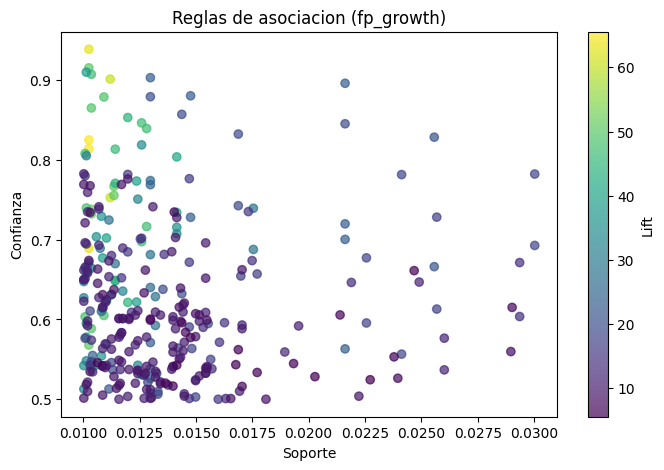

In [35]:
reglas.graficar_reglas("fp_growth")

In [36]:
reglas.guardar_reglas("fp_growth", "reglas_asociacion.csv")

Guardado en: reglas_asociacion.csv


In [37]:
"""pipeline.convertir_tipos(
    columnas_int=["CustomerID"],
    columnas_fecha=["InvoiceDate"]
)

pipeline.filtrar_facturas_canceladas(
    obtener=False
)

pipeline.tratar_nulos(
    columnas=["Description"], # Se poseen suficientes valores para trabajar. 
    metodo="eliminar"        # Ademas, es una cantidad muy pequeña y es la variable objetivo
)

pipeline.eliminar_columnas(["CustomerID"]) # No es necesaria para el analisis
pipeline.analizar()"""

'pipeline.convertir_tipos(\n    columnas_int=["CustomerID"],\n    columnas_fecha=["InvoiceDate"]\n)\n\npipeline.filtrar_facturas_canceladas(\n    obtener=False\n)\n\npipeline.tratar_nulos(\n    columnas=["Description"], # Se poseen suficientes valores para trabajar. \n    metodo="eliminar"        # Ademas, es una cantidad muy pequeña y es la variable objetivo\n)\n\npipeline.eliminar_columnas(["CustomerID"]) # No es necesaria para el analisis\npipeline.analizar()'